# Decoding a multi-nanobubble configuration from its DOS

A target log-DOS spectrum $y(E)$ is modelled as the logarithm of a non-negative mixture of single-bubble spectra,

$$y(E) \approx \log \sum_{i=1}^{76} w_i\,\mathrm{DOS}_i(E), \qquad 0 \le w_i \le 1 ,$$

and the $w_i$ are the kernel of a single dense layer. After fitting, the weights *are* the configuration:
which bubbles $(\sigma, h)$ are present and in which proportion.

Part 1 needs only the shipped checkpoints; part 2 needs the DOS library (see `data/README.md`).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
import numpy as np
import matplotlib.pyplot as plt
from nanobubble import BASIS_LABELS, read_weights, parse_checkpoint_name, score_weights, basis_index
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

## 1. Reading a trained network

In [2]:
path = '../pretrained/random_mixtures/N5__s20h24+s20h02+s30h18+s30h20+s30h00.hdf5'
truth = parse_checkpoint_name(path)
w = read_weights(path)
print('true configuration :', truth['labels'], '(each 1/5)')
print('weights >= 0.01    :', {BASIS_LABELS[i]: round(float(w[i]), 5) for i in np.flatnonzero(w >= 0.01)})
print(score_weights(w, [basis_index(l) for l in truth['labels']]))

true configuration : [(20, 24), (20, 2), (30, 18), (30, 20), (30, 0)] (each 1/5)
weights >= 0.01    : {(30, 0): 0.2, (20, 2): 0.2, (30, 18): 0.2, (30, 20): 0.2, (20, 24): 0.2}
{'exact_support': True, 'n_true': 5, 'n_pred': 5, 'false_pos': 0, 'false_neg': 0, 'rel_l2_error_pct': 6.458494364330846e-05, 'max_abs_error': 1.919090237834098e-07, 'weight_sum': 1.000000360112698}


A repeated constituent shows up as a larger weight (k/N), not as an extra basis:

In [3]:
w = read_weights('../pretrained/repeated/N3__s30h20+s30h20+s30h11.hdf5')
print({BASIS_LABELS[i]: round(float(w[i]), 5) for i in np.flatnonzero(w >= 0.01)})

{(30, 11): 0.33333, (30, 20): 0.66667}


## 2. Fitting a new noisy target (needs the DOS library)

In [4]:
from nanobubble import build_library, make_target
from nanobubble.fit import solve_bounded
from nanobubble.baselines import nnls_linear
E, X, labels = build_library(os.environ.get('NANOBUBBLE_DATA_DIR'))
idx = [basis_index(l) for l in [(20, 4), (25, 7), (30, 10)]]
y = make_target(X, idx, snr=0.03, rng=np.random.default_rng(1))

w_ours, loss = solve_bounded(X, y)      # same objective as the Keras model, L-BFGS-B
w_nnls = nnls_linear(X, y)              # conventional NNLS on the linear DOS
for name, w in [('log-domain fit', w_ours), ('NNLS (linear)', w_nnls)]:
    s = score_weights(w, idx)
    print(f"{name:15s} detected {s['n_pred']:2d}  exact={s['exact_support']}  weight error {s['rel_l2_error_pct']:.1f} %")

log-domain fit  detected  3  exact=True  weight error 5.1 %
NNLS (linear)   detected  4  exact=False  weight error 15.2 %


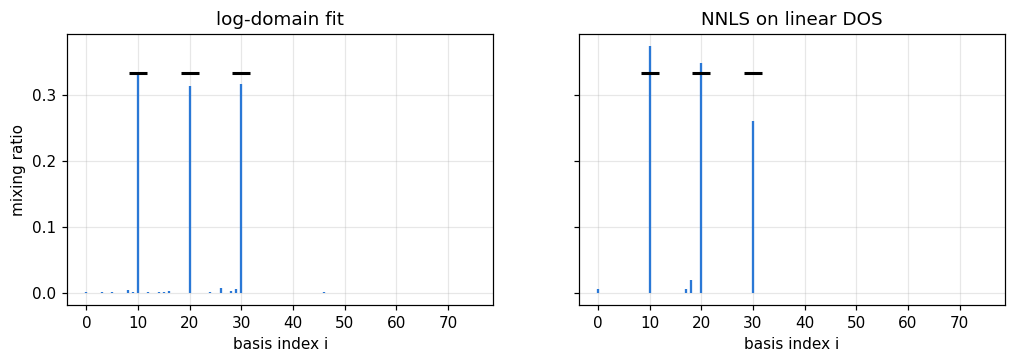

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for a, w, t in [(ax[0], w_ours, 'log-domain fit'), (ax[1], w_nnls, 'NNLS on linear DOS')]:
    a.vlines(range(76), 0, w, color='#2a78d6'); a.plot(idx, [1/3]*3, '_', color='k', ms=12, mew=2)
    a.set_title(t); a.set_xlabel('basis index i')
ax[0].set_ylabel('mixing ratio'); plt.show()

The log-domain loss weights every energy equally in relative terms, so the sharp, many-orders-of-magnitude
resonances do not dominate the fit; linear-space regression is pulled by the largest DOS values and by the
multiplicative noise. A systematic comparison is in `scripts/compare_baselines.py`.